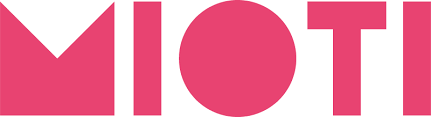

<center style="color:#888">Camilo Gil, Miguel Villasan </center>

<center>Proyecto final Máster MDB2209A:</center>

# **Scoring de clientes para campaña Cmax Azierta**

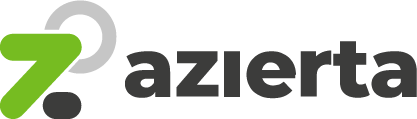

## **Introducción del caso de trabajo:**

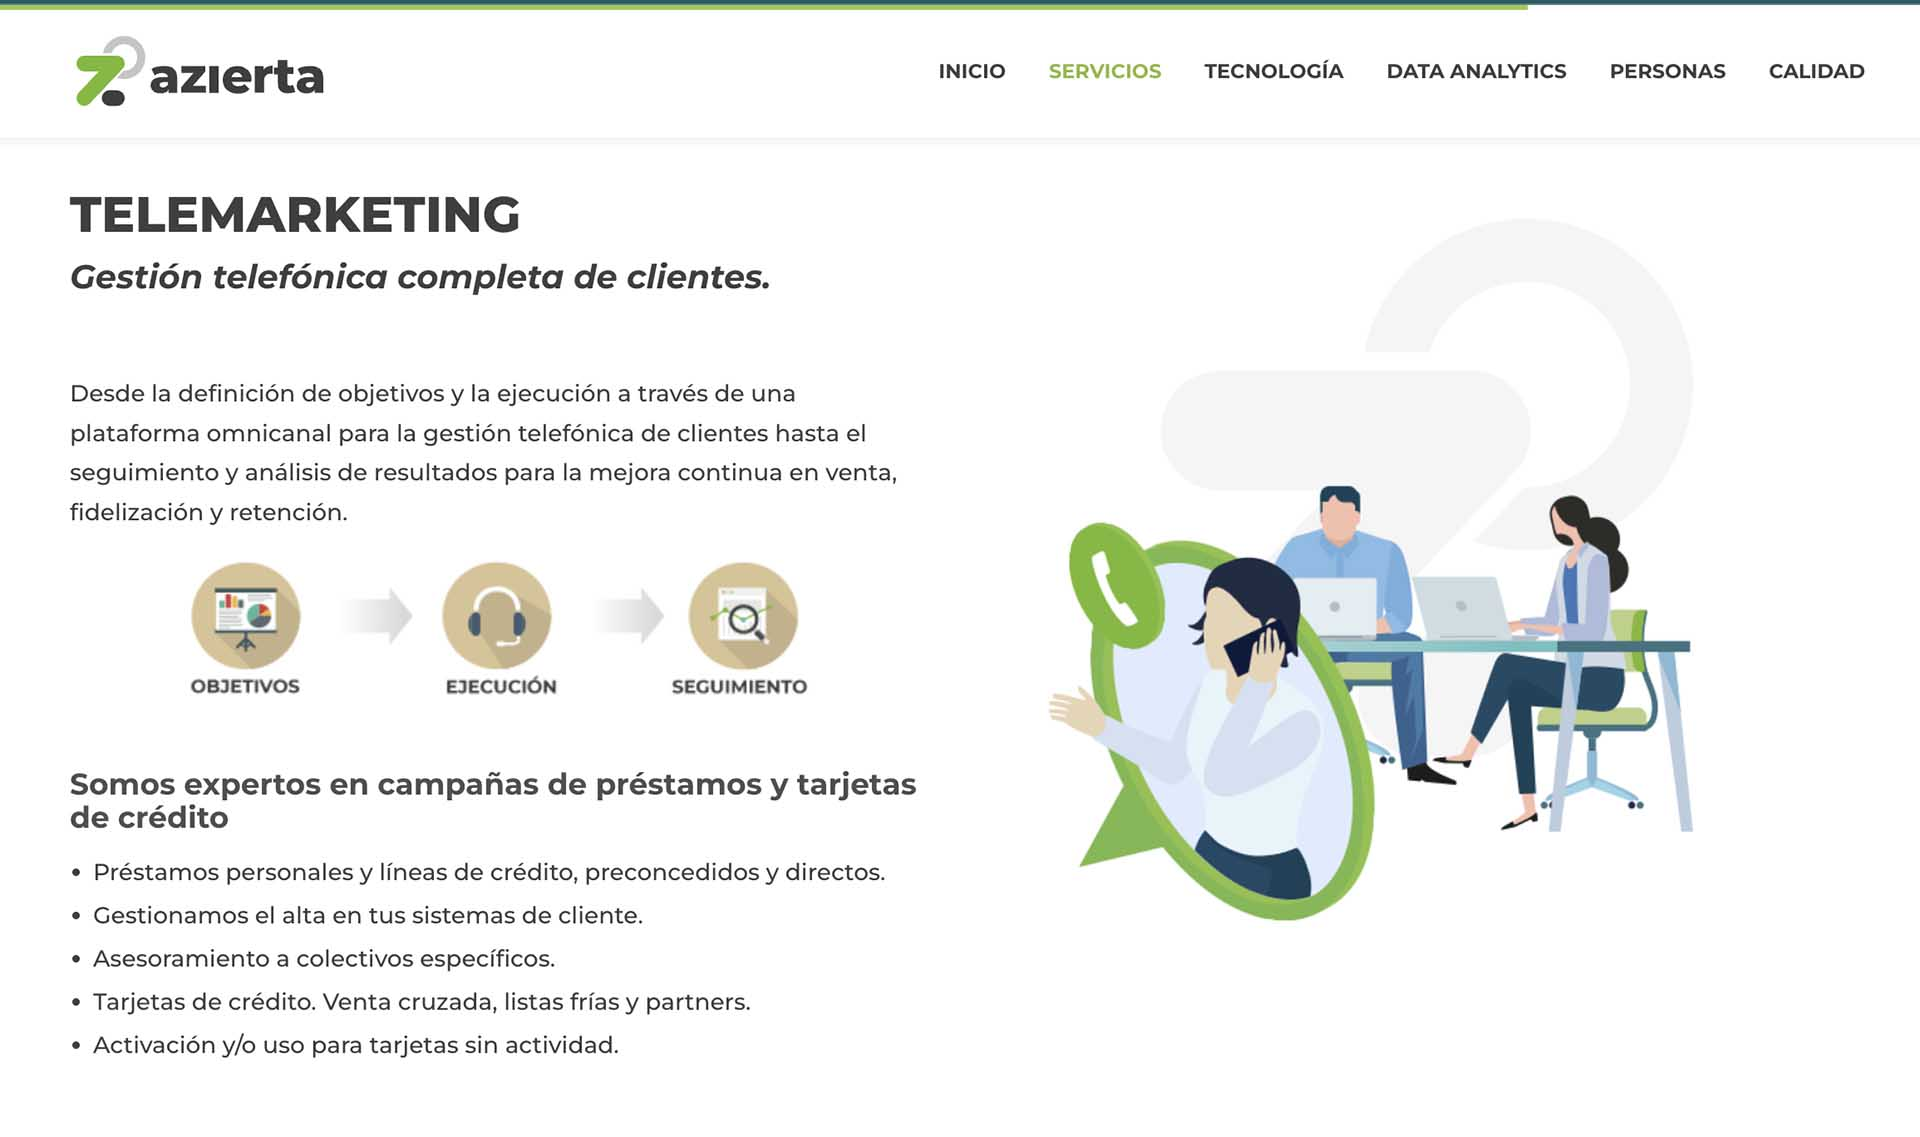

**DESCRIPCIÓN DEL PROYECTO**
- En los últimos años el avance de la tecnología ha permitido el desarrollo de modelos estadisticos cada vez mas robustos y precisos que permiten predecir y evaluar las probabilidades de compra de un producto especifico para determinados clientes. 

- En este proyecto implementaremos para la compañía Azierta Servicios Financieros un modelo de Data Science para la campaña de Bankinter Consumer Finance - CrediMax. 

- El objetivo del proyecto es efectuar un scoring de clientes basado en la información proporcionada por la compañía, el uso de Python con sus respectivas librerias de Machine Learning y el apoyo del área de Analytics de la empresa. 

- Los resultados del modelo proporcionaran herramientas a la compañía para una mejor gestión de clientes, aumentando la eficiencia en cumplimiento de metas que conlleven a beneficios financieros. 

 

## **Importación de los datasets y librerías**:

In [506]:
#Importamos librerías para el manejo de los datos
import pandas as pd
import numpy as np
import sklearn

#Librerías para la visualización de los datos
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
import plotly.express as px
import matplotlib
import matplotlib.pylab as pylab
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
%matplotlib inline
matplotlib.rcParams.update({'font.size': 14})


import seaborn as sns
from seaborn import boxplot
from seaborn import lmplot

#Import MinMaxScaler module para escalar la data
from sklearn.preprocessing import MinMaxScaler

# Importamos las librerías para el análisis de PCA
import statsmodels.api as sm
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import scale
from sklearn.pipeline import Pipeline

# Configuración warnings
import warnings
warnings.filterwarnings('ignore')

#Librería para separar la data 
from sklearn.model_selection import train_test_split

#Librería para tomar en cuenta dataset desbalanceado
from sklearn.utils import class_weight
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.datasets import make_classification

#Librerías de los modelos con los que entrenaremos nuestro dataset
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost.sklearn import XGBClassifier 

#Matriz de confusión y Métricas para evaluar los modelos
from sklearn.metrics import confusion_matrix
#from sklearn.metrics import plot_confusion_matrix

#Métricas de evaluación de algoritmos de machine learning
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report

from sklearn import preprocessing
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.ensemble import BalancedBaggingClassifier 

#Cross Validation ante el desbalanceo de la data
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import LeaveOneOut

#Desbalanceo de los datos
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

#Algunas funciones matemáticas
from numpy import mean
from numpy import absolute
from numpy import std
from statistics import stdev
import scipy.stats as stats

#Optimización de hiperparámetros
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

In [507]:
#importamos scikiplot
!pip install scikit-plot
import scikitplot as skplt

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [508]:
#enlazamos el google drive con el Colaboratory para un manejo mas eficiente
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [509]:
#Enlace del proyecto Azierta Servicios Financieros
import sys    
path_to_module = '/content/drive/Shareddrives/Proyecto Final MDB2209A'
sys.path.append(path_to_module)

In [510]:
#importamos librerias personales
from graphs import grouped_bar_plot
from utils import transform_rgba_color_scale_from_255_to_1, plot_color_scales

## **Elección de las variables significativas para el proyecto:**

- Realizamos un estudio preliminar de las variables, para lo que se requiere el asesoramiento del head of data de la compañía.

- Efectuamos una revisión variable a variable para identificar si son idóneas para el modelo. Algunas variables serán analizadas más a fondo para confirmar si son útiles o no  para el proyecto. En caso de ser variables ruido, serán eliminadas directamente desde la carga de la información.

## **Breve descripción de las variables utilizadas:** 

> *VARIABLES TEMPORALES*

*   t_nacimiento = Fecha de nacimiento.

*   d_venta = Día de la venta.

*   d_cancelación = Día de cancelación de la venta.

*   fechaUltimoCmax = Fecha ultimo credimax.

*   t_contacto_ultimo = Fecha de último contacto con el cliente .

> *VARIABLES CATEGÓRICAS*

*   id_final = Codificación del tipo de final.

*   s_sexo = Sexo del cliente.

*   s_poblacion = Denota la ciudad del cliente.

*   s_codigo_postal = Codigo postal del cliente.

*   ind_anulada_cliente = Indica si la venta fue anulada (TRUE) o no (FALSE) por el cliente. 

*   id_persona = Código de identificación del usuario en una respectiva campaña.

> *VARIABLES NUMÉRICAS*

*   n_contactos_realizados = Número de veces que se llama al registro(id persona e inicio validez).

*   duración = duración de la llamada en segundos.

*   imp_venta = Importe de la venta.

*   n_dias_cancelacion = Cantidad de dias a los que se canceló la venta.

*   limiteTarjeta = Límite de la tarjeta.

*   importe_solicitado = Importe solicitado.

*   limiteCmax = Límite Cmax.

*   importeUltimoCmax = Importe último Cmax.


> *VARIABLE TARGET*

*   id_final = Identificador de estado final del cliente (si se ha producido la compra, si ha habido respuesta negativa, etc.)

*   y_predict_proba = Scoring del cliente generado por el modelo

### **Anonimización de los datos y carga de los datasets**:



- Debido a que los datos para este proyecto son de carácter sensible por tratarse de operaciones bancarias, es necesaria la anonimización de los mismos. Para ello se elimina de los csv cualquier información relativa a nombres y direcciones así como información personal de cualquier tipo.

- Se procede a crear un campo "id_persona" que será un identificador único, común en todos los datasets.

## **Carga inicial de los datos:**

In [511]:
#Leemos el archivo y eliminamos variable no necesaria para el modelo
TLMK_BKCF_CMAX_VENTA = pd.read_csv('/content/drive/Shareddrives/Proyecto Final MDB2209A/DATA/TLMK Cmax_venta.csv')
TLMK_BKCF_CMAX_VENTA = TLMK_BKCF_CMAX_VENTA.drop('d_cancelacion', axis=1)
TLMK_BKCF_CMAX_VENTA.head()

,id_persona,d_venta,imp_venta,id_final,ind_anulada_cliente,n_dias_cancelacion
0,100707328,2022-09-20,500.0,502,False,NaN
1,101016140,2022-09-09,2500.0,501,False,NaN
2,100990570,2022-07-19,3000.0,501,False,NaN
3,101152172,2022-10-19,500.0,501,False,NaN
4,101438838,2022-12-30,3000.0,501,False,NaN


In [512]:
#Leemos el archivo
TLMK_PERSONA = pd.read_csv('/content/drive/Shareddrives/Proyecto Final MDB2209A/DATA/TLMK persona Cmax.csv')
TLMK_PERSONA.head()

,id_persona,s_codigo_postal,t_nacimiento,s_sexo,s_poblacion
0,101260196,33213,1961-03-28 00:00:00.000,H,GIJON
1,101016747,46025,1981-01-18 00:00:00.000,M,VALENCIA
2,100965644,30877,1969-01-12 00:00:00.000,H,BOLNUEVO
3,101056977,48014,1955-03-21 00:00:00.000,H,BILBAO
4,100846951,42120,1969-08-09 00:00:00.000,H,GOMARA


In [513]:
#Leemos el archivo y eliminamos las variables no necesarias para el modelo 
TLMK_PERSONA_CAMPANYA = pd.read_csv('/content/drive/Shareddrives/Proyecto Final MDB2209A/DATA/TLMK persona_campanya Cmax.csv')
TLMK_PERSONA_CAMPANYA = TLMK_PERSONA_CAMPANYA.drop(['t_contacto_proximo','n_finales_consecutivos',
                                                    'n_contactos_max','n_contactos_pendientes',
                                                    'n_segundos_consumidos', 'id_estado_registro','t_inicio_validez','t_final_validez', 't_intento_contacto_ultimo','n_intentos_contacto_realizados'],axis=1)
TLMK_PERSONA_CAMPANYA.head()

,id_persona,id_final,t_contacto_ultimo,n_contactos_realizados
0,100554075,311,2022-09-09 18:35:37.163,1
1,100554099,406,2022-09-06 16:38:45.307,2
2,100554203,311,2022-09-09 18:35:37.237,2
3,100554217,307,2022-09-12 21:34:12.680,2
4,100554237,406,2022-09-22 15:17:35.233,5


In [514]:
#Leemos el archivo
TLMK_PERSONA_IMPORTE_SOLICITADO = pd.read_csv('/content/drive/Shareddrives/Proyecto Final MDB2209A/DATA/TLMK persona_datos DataWharehouse importe solicitado.csv')
TLMK_PERSONA_IMPORTE_SOLICITADO.head()

,id_persona,s_clave,s_valor
0,100554066,importe_solicitado,NaN
1,100554075,importe_solicitado,NaN
2,100554076,importe_solicitado,NaN
3,100554081,importe_solicitado,NaN
4,100554084,importe_solicitado,NaN


In [515]:
#Leemos el archivo
TLMK_PERSONA_DATOS = pd.read_csv('/content/drive/Shareddrives/Proyecto Final MDB2209A/DATA/TLMK persona_datos DataWharehouse.csv')
TLMK_PERSONA_DATOS.head()

,id_persona,s_clave,s_valor
0,100554066,fechaAltaCuenta,11/03/2020
1,100554066,fechaUltimoCmax,1/01/1900
2,100554066,importeUltimoCmax,NaN
3,100554066,limiteCmax,4000
4,100554066,limiteTarjeta,4000


In [516]:
#Leemos el archivo y eliminamos las variables no necesarias para el modelo
TLMK_TABLA_LLAMADAS = pd.read_csv('/content/drive/Shareddrives/Proyecto Final MDB2209A/DATA/TLMK llamadas.csv')
TLMK_TABLA_LLAMADAS = TLMK_TABLA_LLAMADAS.drop(['id_campanya', 's_atendida','t_final'],axis=1)

## **Información básica por tabla:**



In [517]:
#Resumen del contenido de la tabla
TLMK_BKCF_CMAX_VENTA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2451 entries, 0 to 2450
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_persona           2451 non-null   int64  
 1   d_venta              2451 non-null   object 
 2   imp_venta            2451 non-null   float64
 3   id_final             2451 non-null   int64  
 4   ind_anulada_cliente  2451 non-null   bool   
 5   n_dias_cancelacion   426 non-null    float64
dtypes: bool(1), float64(2), int64(2), object(1)
memory usage: 98.3+ KB


In [518]:
#Resumen del contenido de la tabla
TLMK_PERSONA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51610 entries, 0 to 51609
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id_persona       51610 non-null  int64 
 1   s_codigo_postal  51610 non-null  int64 
 2   t_nacimiento     51610 non-null  object
 3   s_sexo           51610 non-null  object
 4   s_poblacion      51609 non-null  object
dtypes: int64(2), object(3)
memory usage: 2.0+ MB


In [519]:
#Resumen del contenido de la tabla
TLMK_PERSONA_CAMPANYA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51610 entries, 0 to 51609
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id_persona              51610 non-null  int64 
 1   id_final                51610 non-null  int64 
 2   t_contacto_ultimo       51119 non-null  object
 3   n_contactos_realizados  51610 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.6+ MB


In [520]:
#Resumen del contenido de la tabla
TLMK_PERSONA_IMPORTE_SOLICITADO.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51610 entries, 0 to 51609
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_persona  51610 non-null  int64 
 1   s_clave     51610 non-null  object
 2   s_valor     2605 non-null   object
dtypes: int64(1), object(2)
memory usage: 1.2+ MB


In [521]:
#Resumen del contenido de la tabla
TLMK_PERSONA_DATOS.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 258050 entries, 0 to 258049
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id_persona  258050 non-null  int64 
 1   s_clave     258050 non-null  object
 2   s_valor     217414 non-null  object
dtypes: int64(1), object(2)
memory usage: 5.9+ MB


In [522]:
#Resumen del contenido de la tabla
TLMK_TABLA_LLAMADAS.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 433637 entries, 0 to 433636
Data columns (total 5 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id_final            433637 non-null  int64  
 1   duracion            433637 non-null  float64
 2   s_sentido           433637 non-null  object 
 3   id_persona          433637 non-null  int64  
 4   s_telefono_destino  433637 non-null  object 
dtypes: float64(1), int64(2), object(2)
memory usage: 16.5+ MB


## **Declaración de indices**:

In [523]:
#Definimos id_persona como el index de la tabla
TLMK_BKCF_CMAX_VENTA.set_index('id_persona', inplace = True)

In [524]:
#Definimos id_persona como el index de la tabla
TLMK_PERSONA.set_index('id_persona', inplace = True)

In [525]:
#Definimos id_persona como el index de la tabla
TLMK_PERSONA_CAMPANYA.set_index('id_persona', inplace = True)

In [526]:
#Construimos una pivot table para agrupar los valores de la tabla
TLMK_PERSONA_IMPORTE_SOLICITADO = TLMK_PERSONA_IMPORTE_SOLICITADO.pivot_table(values='s_valor', index='id_persona', columns='s_clave', aggfunc='sum')

In [527]:
#Construimos una pivot table para agrupar los valores de la tabla y eliminamos variable no necesaria
TLMK_PERSONA_DATOS = TLMK_PERSONA_DATOS.pivot_table(values='s_valor', index='id_persona', columns='s_clave', aggfunc='sum')
TLMK_PERSONA_DATOS = TLMK_PERSONA_DATOS.drop('fechaAltaCuenta', axis=1)

## **Data Engineering preliminar:**

In [528]:
#Realizamos un conteo de id_final positivos
TLMK_BKCF_CMAX_VENTA.id_final.value_counts()

501    2311
502     140
Name: id_final, dtype: int64

In [529]:
#Verificamos registros para id_persona = 101264380 como sample
TLMK_TABLA_LLAMADAS[(TLMK_TABLA_LLAMADAS.id_persona == 101264380)]

,id_final,duracion,s_sentido,id_persona,s_telefono_destino
157945,501,0.0,OUT,101264380,5032*1
157946,501,142.0,IN,101264380,601647096
157965,450,28.0,IN,101264380,601647096
159630,409,31.0,IN,101264380,601647096
159637,450,29.0,IN,101264380,601647096
159643,27,931.0,IN,101264380,601647096
159752,450,26.0,IN,101264380,601647096
159808,501,0.0,OUT,101264380,5032*1
159809,501,255.0,IN,101264380,601647096
160028,501,0.0,OUT,101264380,5032*1


In [530]:
#Identificamos un teléfono de destino inusual, el cúal se refiere a la verificación de las ventas Credimax
TLMK_TABLA_LLAMADAS[
                    (TLMK_TABLA_LLAMADAS.s_telefono_destino == '5032*2') |
                    (TLMK_TABLA_LLAMADAS.s_telefono_destino == '5032*1')
                    ]

,id_final,duracion,s_sentido,id_persona,s_telefono_destino
150,501,0.0,OUT,101442723,5032*2
261,501,0.0,OUT,100556344,5032*1
1007,501,0.0,OUT,101442034,5032*2
1009,501,1.0,OUT,101442532,5032*2
1071,501,0.0,OUT,101440692,5032*1
...,...,...,...,...,...
433451,501,1.0,OUT,100935157,5032*1
433453,501,0.0,OUT,100936242,5032*1
433500,501,0.0,OUT,100940588,5032*2
433542,501,0.0,OUT,100940588,5032*2


In [531]:
#Se eliminan los registros de llamadas automáticas de confirmación hechas por el sistema
TLMK_TABLA_LLAMADAS = TLMK_TABLA_LLAMADAS[(TLMK_TABLA_LLAMADAS.s_telefono_destino != '5032*2') & 
                                          (TLMK_TABLA_LLAMADAS.s_telefono_destino != '5032*1')]

In [532]:
#Creamos una columna nueva para alojar los id_final y proceder a su categorización
TLMK_TABLA_LLAMADAS['estado_negocio'] = TLMK_TABLA_LLAMADAS['id_final']

In [533]:
#Agrupamos los valores de id_final por categorías para mayor eficiencia
Nulos= [300,301,302,303,304,306,307,308,309,310,311]
Positivos=[501,502]
Negativos=[400,401,403,405,406,409,414,415,451,416,500,600]
Inicial= 100
Reprogramado=[17,201,202,203,450,204]
Reprogramado_argumentado=200
Sistema=[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,18,19,20,21,22,23,24,25,26,27]

In [534]:
#Reemplazamos los valores de la columna por las categorías creadas y eliminamos la columna id_final
TLMK_TABLA_LLAMADAS['estado_negocio']=TLMK_TABLA_LLAMADAS['estado_negocio'].replace(to_replace=Nulos,value='NULOS' )
TLMK_TABLA_LLAMADAS['estado_negocio']=TLMK_TABLA_LLAMADAS['estado_negocio'].replace(to_replace=Positivos,value='POSITIVO' )
TLMK_TABLA_LLAMADAS['estado_negocio']=TLMK_TABLA_LLAMADAS['estado_negocio'].replace(to_replace=Negativos,value='NEGATIVO' )
TLMK_TABLA_LLAMADAS['estado_negocio']=TLMK_TABLA_LLAMADAS['estado_negocio'].replace(to_replace=Inicial,value='INICIAL' )
TLMK_TABLA_LLAMADAS['estado_negocio']=TLMK_TABLA_LLAMADAS['estado_negocio'].replace(to_replace=Reprogramado,value='REPROGRAMADO' )
TLMK_TABLA_LLAMADAS['estado_negocio']=TLMK_TABLA_LLAMADAS['estado_negocio'].replace(to_replace=Reprogramado_argumentado,value='REPROGRAMADO_ARGUMENTADO')
TLMK_TABLA_LLAMADAS['estado_negocio']=TLMK_TABLA_LLAMADAS['estado_negocio'].replace(to_replace=Sistema,value='SISTEMA')
TLMK_TABLA_LLAMADAS = TLMK_TABLA_LLAMADAS.drop('id_final',axis=1)

In [535]:
#Cantidades por estado de negocio
TLMK_TABLA_LLAMADAS['estado_negocio'].value_counts()

SISTEMA                     330012
REPROGRAMADO                 52581
NEGATIVO                     34030
REPROGRAMADO_ARGUMENTADO      5663
NULOS                         5200
POSITIVO                      3096
Name: estado_negocio, dtype: int64

In [536]:
#Se reemplazan valores en los strings relativos a números de teléfono para su posterior categorización
TLMK_TABLA_LLAMADAS['s_telefono_destino'] = TLMK_TABLA_LLAMADAS['s_telefono_destino'].str.replace(r'\*\d{2}', '')
TLMK_TABLA_LLAMADAS['s_telefono_destino'] = np.where(
                                            TLMK_TABLA_LLAMADAS['s_telefono_destino'].str.startswith('34'),
                                            TLMK_TABLA_LLAMADAS['s_telefono_destino'].str[2:], 
                                            TLMK_TABLA_LLAMADAS['s_telefono_destino']
                                            )
TLMK_TABLA_LLAMADAS

,duracion,s_sentido,id_persona,s_telefono_destino,estado_negocio
0,59.0,IN,101011662,621185690,NEGATIVO
1,115.0,OUT,101439639,699919553,SISTEMA
2,0.0,OUT,101438725,952239264,SISTEMA
3,21.0,OUT,101012477,916687093,REPROGRAMADO
4,28.0,OUT,101013919,963515461,SISTEMA
...,...,...,...,...,...
433632,10.0,OUT,100935513,635552207,REPROGRAMADO
433633,12.0,OUT,100935503,934908395,NULOS
433634,9.0,OUT,100940111,618018143,REPROGRAMADO
433635,70.0,OUT,100939986,698354753,REPROGRAMADO_ARGUMENTADO


In [537]:
#Se detectan números de teléfono que no comienzan por 6 o 9 y que corresponden a teléfonos móviles
TLMK_TABLA_LLAMADAS[~(
    (TLMK_TABLA_LLAMADAS['s_telefono_destino'].str.startswith('6')) | 
    (TLMK_TABLA_LLAMADAS['s_telefono_destino'].str.startswith('9'))
    )]

,duracion,s_sentido,id_persona,s_telefono_destino,estado_negocio
43,2.0,OUT,101443240,871933490,SISTEMA
49,2.0,OUT,100883318,856103676,SISTEMA
778,0.0,OUT,101438986,868109482,SISTEMA
896,27.0,OUT,101440656,722410353,SISTEMA
927,5.0,OUT,101443349,856211958,SISTEMA
...,...,...,...,...,...
433162,0.0,OUT,100938364,727776047,SISTEMA
433280,2.0,OUT,100938558,822014689,SISTEMA
433283,22.0,OUT,100938251,856129373,REPROGRAMADO
433300,2.0,OUT,100938940,871534050,SISTEMA


In [538]:
#Se categorizan los valores de números de teléfono a su clase (fijo, móvil) 
TLMK_TABLA_LLAMADAS['telefono'] = np.where(
                                      (TLMK_TABLA_LLAMADAS['s_telefono_destino'].str.startswith('6')) | 
                                      (TLMK_TABLA_LLAMADAS['s_telefono_destino'].str.startswith('7')) | 
                                      (TLMK_TABLA_LLAMADAS['s_telefono_destino'].str.startswith('8')),
                                      'MÓVIL', 'FIJO'
                                      )
#Creamos una nueva tabla para realizar el merge sobre el DataFrame para el modelo
TABLA_LLAMADAS_to_merge = TLMK_TABLA_LLAMADAS.drop(['s_telefono_destino'],axis=1)
TABLA_LLAMADAS_to_merge


,duracion,s_sentido,id_persona,estado_negocio,telefono
0,59.0,IN,101011662,NEGATIVO,MÓVIL
1,115.0,OUT,101439639,SISTEMA,MÓVIL
2,0.0,OUT,101438725,SISTEMA,FIJO
3,21.0,OUT,101012477,REPROGRAMADO,FIJO
4,28.0,OUT,101013919,SISTEMA,FIJO
...,...,...,...,...,...
433632,10.0,OUT,100935513,REPROGRAMADO,MÓVIL
433633,12.0,OUT,100935503,NULOS,FIJO
433634,9.0,OUT,100940111,REPROGRAMADO,MÓVIL
433635,70.0,OUT,100939986,REPROGRAMADO_ARGUMENTADO,MÓVIL


In [539]:
#Excluimos todas las llamadas menores a 15 segundos de duración
TLMK_TABLA_LLAMADAS= TLMK_TABLA_LLAMADAS[TLMK_TABLA_LLAMADAS['duracion'] >15]

In [540]:
#Se procede a la creación de columnas por cada categoría creada para completar el histórico de llamadas por cliente
TABLA_LLAMADAS_to_merge = pd.get_dummies(TLMK_TABLA_LLAMADAS, columns=['s_sentido', 'estado_negocio', 'telefono'])
TABLA_LLAMADAS_to_merge

,duracion,id_persona,s_telefono_destino,s_sentido_IN,s_sentido_OUT,estado_negocio_NEGATIVO,estado_negocio_NULOS,estado_negocio_POSITIVO,estado_negocio_REPROGRAMADO,estado_negocio_REPROGRAMADO_ARGUMENTADO,estado_negocio_SISTEMA,telefono_FIJO,telefono_MÓVIL
0,59.0,101011662,621185690,1,0,1,0,0,0,0,0,0,1
1,115.0,101439639,699919553,0,1,0,0,0,0,0,1,0,1
3,21.0,101012477,916687093,0,1,0,0,0,1,0,0,1,0
4,28.0,101013919,963515461,0,1,0,0,0,0,0,1,1,0
7,28.0,101013085,616892126,0,1,0,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
433624,68.0,100938398,680325900,0,1,0,0,0,0,0,1,0,1
433626,73.0,100937781,615377001,0,1,0,0,0,0,0,1,0,1
433630,30.0,100939072,917393531,0,1,0,0,0,0,0,1,1,0
433635,70.0,100939986,698354753,0,1,0,0,0,0,1,0,0,1


In [541]:
#Unificamos los valores haciendo una agrupación por id de cliente
TABLA_LLAMADAS_to_merge = TABLA_LLAMADAS_to_merge.groupby('id_persona').sum()

## **Merging Dataframes**:

In [542]:
#Realizamos el merge de DataFrames TLMK_PERSONA y TLMK_PERSONA_CAMPANYA
df = pd.merge(TLMK_PERSONA, TLMK_PERSONA_CAMPANYA, how='outer', left_index=True, right_index=True)

In [543]:
#Realizamos el merge del DataFrame anteior y TLMK_PERSONA_IMPORTE_SOLICITADO
df = pd.merge(df, TLMK_PERSONA_IMPORTE_SOLICITADO, how='outer', left_index=True, right_index=True)

In [544]:
#Realizamos el merge del DataFrame anterior y TLMK_PERSONA_DATOS
df = pd.merge(df, TLMK_PERSONA_DATOS, how='outer', left_index=True, right_index=True)

In [545]:
#Realizamos el merge del DataFrame anterior y TLMK_PERSONA_IMPORTE_SOLICITADO
df = pd.merge(df, TLMK_BKCF_CMAX_VENTA, how='outer', left_index=True, right_index=True)

In [546]:
#Realizamos el merge del DataFrame anterior y TLMK_PERSONA_IMPORTE_SOLICITADO
df = pd.merge(df, TABLA_LLAMADAS_to_merge, how='inner', on='id_persona')

## **Primer acercamiento a los datos:**

In [547]:
#Dar un primer vistazo a los datos
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 39521 entries, 100554066 to 101443567
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   s_codigo_postal                          39521 non-null  int64  
 1   t_nacimiento                             39521 non-null  object 
 2   s_sexo                                   39521 non-null  object 
 3   s_poblacion                              39520 non-null  object 
 4   id_final_x                               39521 non-null  int64  
 5   t_contacto_ultimo                        39442 non-null  object 
 6   n_contactos_realizados                   39521 non-null  int64  
 7   importe_solicitado                       39521 non-null  object 
 8   fechaUltimoCmax                          39521 non-null  object 
 9   importeUltimoCmax                        39521 non-null  object 
 10  limiteCmax                        

In [548]:
#pd.set_option('max_columns', None)
#df.sample()

In [549]:
#Información del DataSet
print('Shape DataSet: '+ str(df.shape))

Shape DataSet: (39521, 28)


In [550]:
#Investigar si existen datos duplicados
datadup = df.loc[df.duplicated() == True]
print('Datos duplicados: '+ str(len(datadup)))

Datos duplicados: 0


**Observaciones:**

>El dataset combinado tiene un total en 28 columnas y 39521 registros. Los datos son tanto numéricos como categóricos del tipo int, float,object por lo que es necesario un tratamiento de la información.

##**Transformaciones tipo de dato:**

In [551]:
#Ajuste formato de datos numéricos
df['importe_solicitado'] = df['importe_solicitado'].str.replace(",", ".").astype(float)
df['importeUltimoCmax'] = df['importeUltimoCmax'].astype(float)
df['limiteCmax'] = df['limiteCmax'].astype(float)
df['limiteTarjeta'] = df['limiteTarjeta'].astype(float)

In [552]:
#Ajuste formato de datos temporales
df['t_nacimiento'] = pd.to_datetime(df['t_nacimiento'], format='%Y-%m-%d %H:%M:%S.%f')
df['t_contacto_ultimo'] = pd.to_datetime(df['t_contacto_ultimo'], format='%Y-%m-%d %H:%M:%S.%f')
df['d_venta'] = pd.to_datetime(df['d_venta'], format='%Y-%m-%d')

In [553]:
#Se reemplazan valores 0 por NaN para poder cambiar las columnas a formato datetime
df['fechaUltimoCmax'] = df['fechaUltimoCmax'].replace([0], [np.nan])

#Ajuste formato de datos temporales
df['fechaUltimoCmax'] = pd.to_datetime(df['fechaUltimoCmax'], format='%d/%m/%Y')

In [554]:
#Cálculo de la edad de clientes según fecha de nacimiento, eliminación de la columna con fecha de nacimiento
ahora = pd.Timestamp('now')
df['t_edad'] = (ahora - df['t_nacimiento']).astype('<m8[Y]')
df['t_edad'] = df['t_edad'].astype(float)
df = df.drop('t_nacimiento',axis=1)

In [555]:
#Se actualizan los datos de la columna id_final_x con las actualizaciones sobre el cliente de id_final_y, se elimina la columna
df['id_final_x'] = df['id_final_x'].where(df['id_final_y'].isna(), df['id_final_y'])
df = df.drop('id_final_y',axis=1)

In [556]:
#Comprobamos el cambio de tipo de dato por columna del DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 39521 entries, 100554066 to 101443567
Data columns (total 27 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   s_codigo_postal                          39521 non-null  int64         
 1   s_sexo                                   39521 non-null  object        
 2   s_poblacion                              39520 non-null  object        
 3   id_final_x                               39521 non-null  int64         
 4   t_contacto_ultimo                        39442 non-null  datetime64[ns]
 5   n_contactos_realizados                   39521 non-null  int64         
 6   importe_solicitado                       2613 non-null   float64       
 7   fechaUltimoCmax                          39476 non-null  datetime64[ns]
 8   importeUltimoCmax                        39521 non-null  float64       
 9   limiteCmax                 

##**Renombramiento de las variables para el modelo:**

**Observaciones:**

>Se renombró el nombre de las variables para un mejor manejo y entendimiento de la información.

In [557]:
#Renombramiento de las columnas para facilitar su uso en el código.
df.columns = ['codigo_postal','sexo','ciudad','id_final', 'fecha_contacto_ultimo', 
       'contactos_realizados','importe_solicitado', 'fecha_ultimo_cmax','importe_ultimo_cmax','limite_max',
       'limite_tarjeta','fecha_venta','importe_venta','venta_anulada','cantidad_dias_cancela',
       'duracion_llamadas', 'llamada_entrante', 'llamada_saliente', 'Final_NEGATIVO',
       'Final_NULOS', 'Final_POSITIVO', 'Final_REPROGRAMADO', 'Final_REPRO_ARGUMENTADO',
       'Final_SISTEMA', 'FIJO', 'MOVIL',  'edad']

## **Análisis Univariado:**

**Variable ciudad**

In [558]:
#Cantidad de contactos por ciudad
df['ciudad'].value_counts().head(5)

MADRID       2845
BARCELONA    1208
VALENCIA      753
SEVILLA       741
MALAGA        607
Name: ciudad, dtype: int64

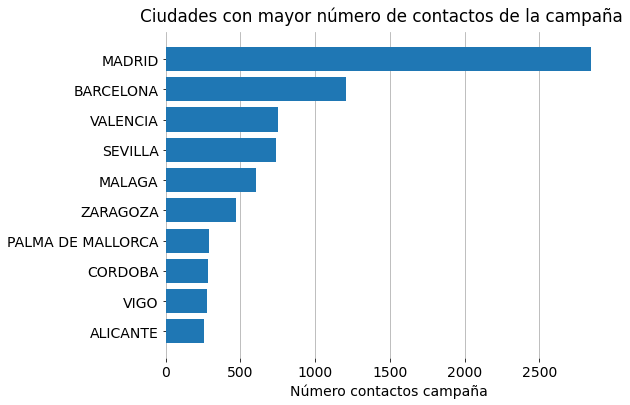

In [559]:
#Se muestran las 10 ciudades con mayor número de contactos en la campaña ordenadas de mayor a menor.
df_city = pd.DataFrame(df['ciudad'].value_counts()).reset_index().head(10).sort_values(
    by='ciudad', ascending=True)


fig, ax = plt.subplots(figsize=(8,6))

ax.barh(df_city['index'], df_city['ciudad'], zorder=2)

ax.grid(True, axis='x')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
 
ax.set_xlabel('Número contactos campaña')

fig.suptitle('Ciudades con mayor número de contactos de la campaña', y=.94);

**Observaciones:**

**Variable id_final**

In [560]:
#Conteo de los diferentes valores de id_final
df['id_final'].value_counts().head(10)

406    10432
311     8191
403     4948
409     4034
501     2312
307     2124
306     1864
309     1073
301      688
1        552
Name: id_final, dtype: int64

In [561]:
#Construimos el counter
df_subset = df.copy()
df_subset['counter'] = 1
df_subset = df_subset[['id_final', 'counter']]
df_subset = df_subset.groupby('id_final').agg('sum').sort_values('counter', ascending=False)
df_subset = df_subset.iloc[:22, :].reset_index()
df_subset['id_final'] = df_subset['id_final'].astype(int)

In [562]:
#identificamos los id_finales positivos, negativos,nulos, reprogramados,sistema, reprogramado argumentado e inicial
df_subset['registro']= df_subset['id_final']
df_subset['registro']=df_subset['registro'].replace(to_replace=Nulos,value='NULOS' )
df_subset['registro']=df_subset['registro'].replace(to_replace=Positivos,value='POSITIVO' )
df_subset['registro']=df_subset['registro'].replace(to_replace=Negativos,value='NEGATIVO' )
df_subset['registro']=df_subset['registro'].replace(to_replace=Inicial,value='INICIAL' )
df_subset['registro']=df_subset['registro'].replace(to_replace=Reprogramado,value='REPROGRAMADO' )
df_subset['registro']=df_subset['registro'].replace(to_replace=Reprogramado_argumentado,value='REPROGRAMADO_ARGUMENTADO')
df_subset['registro']=df_subset['registro'].replace(to_replace=Sistema,value='SISTEMA')
df_subset['id_final'] = df_subset['id_final'].astype(str)
df_subset.sort_values(by='counter', inplace=True)


In [563]:
# Introducimos la escala como una lista de tuplas con formato RGBA.
okabe_ito_scale = [
    (230, 159, 0, 1),
    (86, 180, 233, 1),
    (0, 158, 115, 1),
    (240, 228, 66, 1),
    (0, 114, 178, 1),
    (213, 94, 0, 1),
    (204, 121, 167, 1),
    (0, 0, 0, 1)
]

# Escalamos los valores de 0-255 a 0-1 para que lo entienda Matplotlib.
okabe_ito_scale = transform_rgba_color_scale_from_255_to_1(okabe_ito_scale)

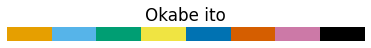

In [564]:
fig, ax = plt.subplots(figsize=(6.4, 0.26))

# Añadimos el título.
ax.set_title("Okabe ito")

# Generamos la matriz a representar.
color_values = np.arange(8).reshape(1, 8)

# Representamos la matriz con la escala Okabe ito.
ax.imshow(color_values, aspect='auto', cmap=ListedColormap(okabe_ito_scale))

# Ocultamos los ejes.
ax.set_axis_off()

In [565]:
def plot_id_final(color_scale, highlight_registro=[]):

    # Generamos los diccionarios que mapean continentes con colores y la leyenda con este mapeo.
    registro_color_map = dict()
    highlight_registro_color_map = dict()
    legend_entries = list()

    for i, registro in enumerate(df_subset['registro'].unique()):
        if highlight_registro:
            color = color_scale[i*2+1]
            registro_color_map[registro] = color

            highlight_color = color_scale[i*2]
            highlight_registro_color_map[registro] = highlight_color
        else:
            color = color_scale[i]
            registro_color_map[registro] = color

        legend_entry = mpatches.Patch(color=color, label=registro)
        legend_entries.append(legend_entry)

    # Obtenemos las columnas a representar.
    id_finales = df_subset['id_final']
    cantidad = df_subset['counter']
    
    # Calculamos los colores que le corresponde a cada línea.
    registros = df_subset['registro']
    registros_colors = [
        highlight_registro_color_map[registro] if registro in highlight_registro 
        else registro_color_map[registro] for registro, id_finales in zip(registros, id_finales)
    ]
    
    # Instanciamos la figura.
    fig, ax = plt.subplots(figsize=(20, 10))
    
    # Añadimos unas guías verticales.
    ax.grid(True, axis='x')

    # Representamos las líneas.
    ax.barh(id_finales, cantidad, color=registros_colors)

    # Añadimos la leyenda.
    ax.legend(handles=legend_entries)

    # Ocultamos el marco.
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    # Etiquetamos el eje X.
    ax.set_xlabel('')

    return fig, ax

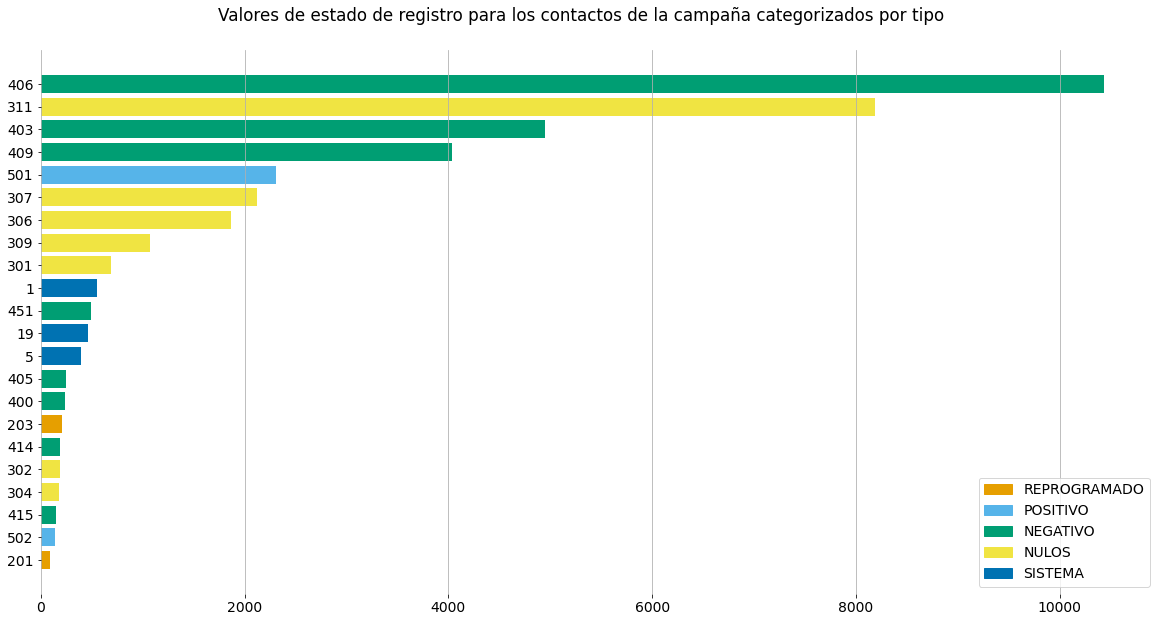

In [566]:
fig, ax = plot_id_final(okabe_ito_scale)

fig.suptitle('Valores de estado de registro para los contactos de la campaña categorizados por tipo', y=.94);

**Variable duración**

In [567]:
#Identificamos los valores estadisticos de la variable
df['duracion_llamadas'].describe()

count    39521.000000
mean       200.225096
std        225.553840
min         16.000000
25%         68.000000
50%        135.000000
75%        257.000000
max       5332.000000
Name: duracion_llamadas, dtype: float64

In [568]:
#Creamos una nueva variable para analizar las llamadas de baja duración
duracion_baja= df['duracion_llamadas'].astype(int)

In [569]:
#duración baja entre 16 y 257 segundos
duracion_baja= duracion_baja[(duracion_baja>= 16)&(duracion_baja<= 257)]

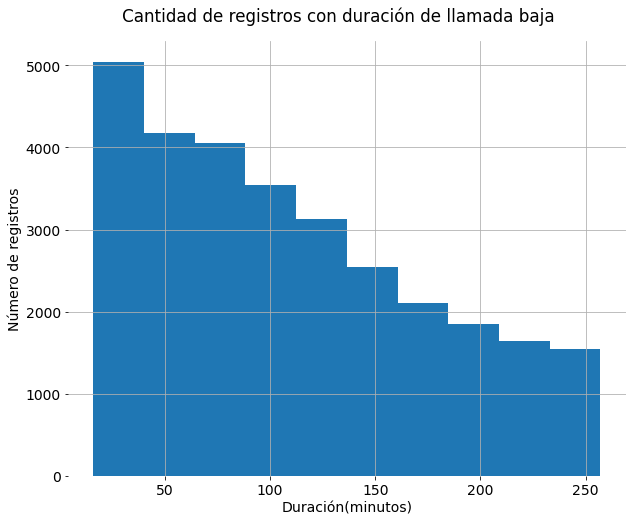

In [570]:
#histograma preliminar
fig, ax = plt.subplots(figsize=(10,8))

ax = duracion_baja.hist(bins=10)

ax.grid(True, axis='x')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xlabel('Duración(minutos)')
ax.set_ylabel('Número de registros')

fig.suptitle('Cantidad de registros con duración de llamada baja', y=.94);

In [571]:
#Creamos una nueva variable para analizar las llamadas de baja media
duracion_media= df['duracion_llamadas'].astype(int)

In [572]:
#duración media entre 258 y 1000 segundos
duracion_media= duracion_media[(duracion_media>= 258)&(duracion_media<= 1000)]

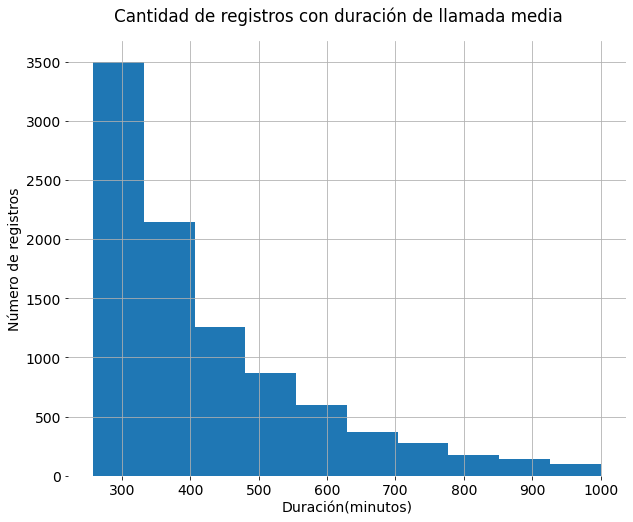

In [573]:
#histograma preliminar
fig, ax = plt.subplots(figsize=(10,8))

ax = duracion_media.hist(bins=10)

ax.grid(True, axis='x')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xlabel('Duración(minutos)')
ax.set_ylabel('Número de registros')

fig.suptitle('Cantidad de registros con duración de llamada media', y=.94);

In [574]:
#Creamos una nueva variable para analizar las llamadas de baja alta
duracion_alta= df['duracion_llamadas'].astype(int)

In [575]:
#duración alta mayores de 1000 segundos
duracion_alta= duracion_alta[(duracion_alta>1000 )]

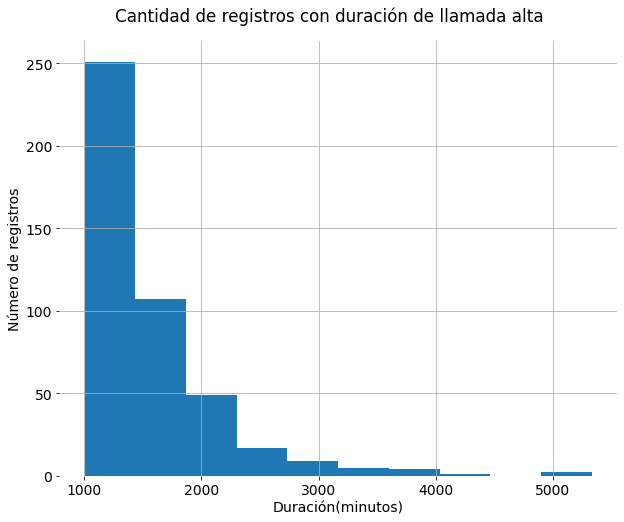

In [576]:
#histograma preliminar
fig, ax = plt.subplots(figsize=(10,8))

ax = duracion_alta.hist(bins=10)

ax.grid(True, axis='x')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xlabel('Duración(minutos)')
ax.set_ylabel('Número de registros')

fig.suptitle('Cantidad de registros con duración de llamada alta', y=.94);

**Variable límite tarjeta**

In [577]:
df['limite_tarjeta'].describe()

count    39521.000000
mean      4479.728499
std       1679.094880
min          0.000000
25%       3000.000000
50%       5000.000000
75%       5000.000000
max      10000.000000
Name: limite_tarjeta, dtype: float64

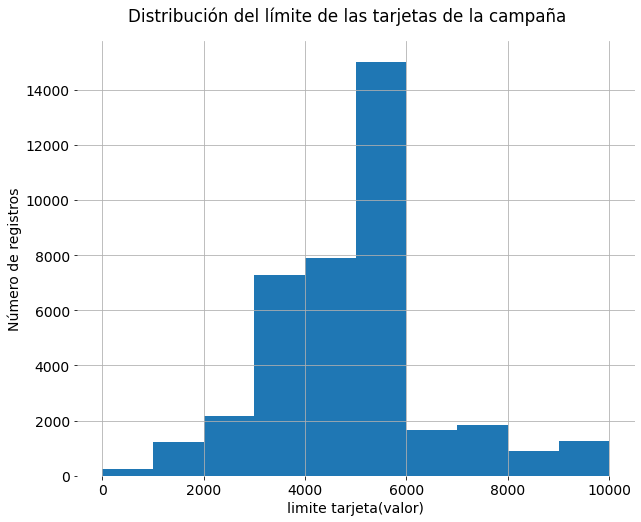

In [578]:
#histograma preliminar
fig, ax = plt.subplots(figsize=(10,8))

ax = df['limite_tarjeta'].hist(bins=10)

ax.grid(True, axis='x')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xlabel('limite tarjeta(valor)')
ax.set_ylabel('Número de registros')

fig.suptitle('Distribución del límite de las tarjetas de la campaña', y=.94);

**Observaciones:**

Identificamos que en cuanto al limite de la tarjeta, el 75% de la población se situa en los 5.000 euros. La mayor cantidad de registros se encuentran entre 3.000 y 6.000 euros.

**Variable límite credimax**

In [579]:
df['limite_max'].describe()

count    39521.000000
mean      3981.349207
std       1586.120828
min        -40.000000
25%       3000.000000
50%       4000.000000
75%       5000.000000
max      10223.000000
Name: limite_max, dtype: float64

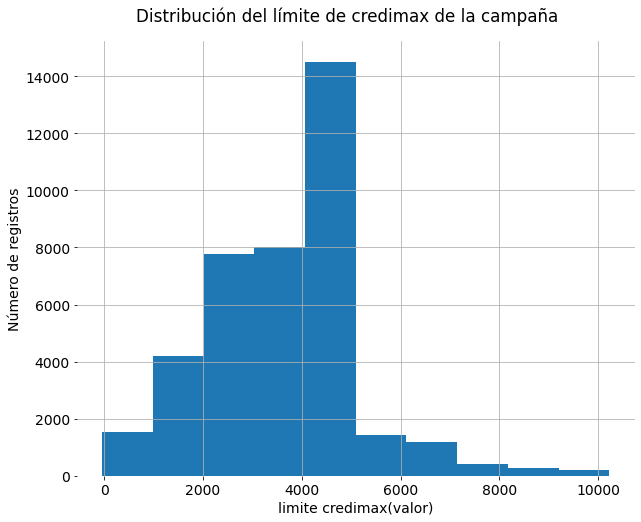

In [580]:
#histograma preliminar
fig, ax = plt.subplots(figsize=(10,8))

ax = df['limite_max'].hist(bins=10)

ax.grid(True, axis='x')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xlabel('limite credimax(valor)')
ax.set_ylabel('Número de registros')

fig.suptitle('Distribución del límite de credimax de la campaña', y=.94);

**Observaciones:**

Identificamos que en cuanto al limite de credimax, el 75% de la población se situa en los 5.000 euros. La mayor cantidad de registros se encuentran entre 3.000 y 5.000 euros.

##**Análisis multivariado**

**Análisis inicial de correlación**

<Axes: >

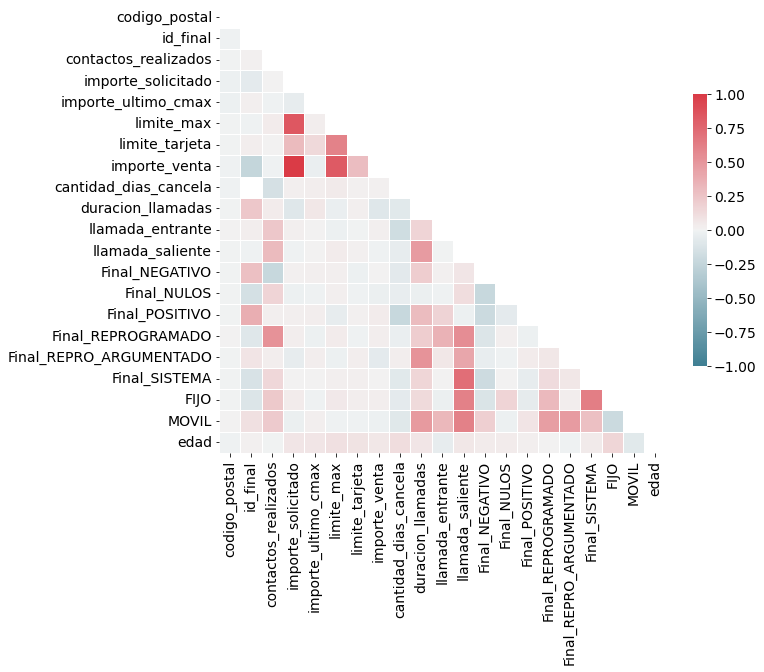

In [581]:
# Matriz de correlación
correlacion = df.corr()

mask = np.zeros_like(correlacion, dtype=np.bool)
mask[np.triu_indices_from(mask)] = True

f, ax = plt.subplots(figsize=(10, 10))

cmap = sns.diverging_palette(220, 10, as_cmap=True)

sns.heatmap(correlacion, mask=mask, cmap=cmap, vmax=1, vmin=-1,
            center=0, square=True, linewidths=.5, cbar_kws={"shrink": .5})

**Observaciones:**



**Variable ciudad, Final_POSITIVO**

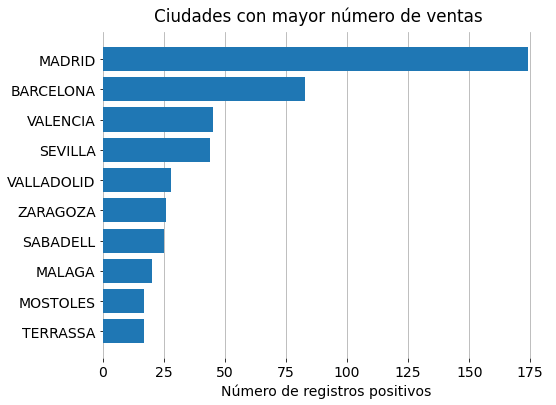

In [582]:
#Se muestran las 10 ciudades con mayor número de registros positivos (ventas) ordenadas de mayor a menor.
df_city = pd.DataFrame(df[df['Final_POSITIVO'] != 0]['ciudad'].value_counts()).reset_index().head(10).sort_values(
    by='ciudad', ascending=True)


fig, ax = plt.subplots(figsize=(8,6))

ax.barh(df_city['index'], df_city['ciudad'], zorder=2)

ax.grid(True, axis='x')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
 
ax.set_xlabel('Número de registros positivos')

fig.suptitle('Ciudades con mayor número de ventas', y=.94);

**Observaciones:**

Identificamos que las ciudades donde se obtienen mayores ventas son Madrid, Barcelona, Valencia y Sevilla respectivamente.

**Variable edad, sexo**

In [583]:
#Estadísticas básicas de la variables
df['edad'].describe()

count    39521.000000
mean        56.124896
std         12.200304
min         21.000000
25%         47.000000
50%         56.000000
75%         65.000000
max         91.000000
Name: edad, dtype: float64

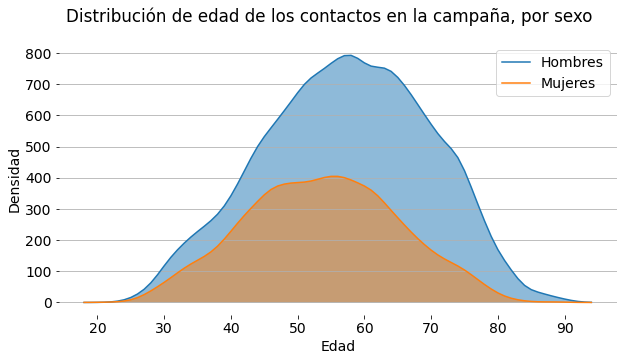

In [584]:
#Análisis variable t_edad por sexo, distribución de edad de los contactos en la campaña
male_ages = df[df['sexo']=='H']['edad']
female_ages = df[df['sexo']=='M']['edad']
distributions_by_sex = [male_ages, female_ages]

x = np.arange(18, 95, 1)

male_age_density_function = stats.kde.gaussian_kde(male_ages.dropna())
male_age_y = male_age_density_function(x)
male_age_y = male_age_y * male_ages.dropna().shape[0]#

female_age_density_function = stats.kde.gaussian_kde(female_ages.dropna())
female_age_y = female_age_density_function(x)
female_age_y = female_age_y * female_ages.dropna().shape[0]#

fig, ax = plt.subplots(figsize=(10,5))

ax.plot(x, male_age_y, label="Hombres")
ax.fill_between(x, male_age_y, alpha=0.5)

ax.plot(x, female_age_y, label="Mujeres")
ax.fill_between(x, female_age_y, alpha=0.5)

ax.grid(True, axis='y')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.legend()

ax.set_xlabel('Edad')
ax.set_ylabel('Densidad')
fig.suptitle("Distribución de edad de los contactos en la campaña, por sexo");

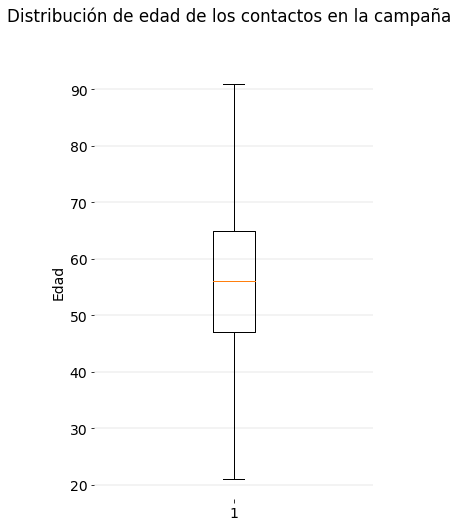

In [585]:
#Análisis variable t_edad, distribución de edad de los contactos en la campaña
fig, ax = plt.subplots(figsize=(5,8))

ax.boxplot(df['edad'].dropna(), zorder=2)

ax.grid(True, axis='y', linewidth=0.3)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_ylabel('Edad')
fig.suptitle("Distribución de edad de los contactos en la campaña");

**Observaciones:**

Logramos identificar una media de edad de 56 años para la población de la campaña. Con un minímo de 21 años y un máximo de 91. El 75% de la población se situa en una edad entre los 47 y los 91 años.

##**Data wrangling:**

### **Tratamiento de duplicados**:

In [586]:
#Identificamos id_persona duplicados en los datos
TLMK_BKCF_CMAX_VENTA.index.value_counts()

101015603    2
100963277    2
100964921    2
100964853    2
100555755    2
            ..
101146771    1
101145283    1
101056417    1
101145237    1
101057675    1
Name: id_persona, Length: 2439, dtype: int64

In [587]:
#Total duplicados
len(TLMK_BKCF_CMAX_VENTA.index) - len(TLMK_BKCF_CMAX_VENTA.index.value_counts()) 

12

In [588]:
#Identificamos que los duplicados hacen referencia a dos ventas hechas al mismo id_persona, el cual tiene importes de venta diferentes
#pd.set_option('max_columns', None)
df[df.index == 100968660]

,codigo_postal,sexo,ciudad,id_final,fecha_contacto_ultimo,contactos_realizados,importe_solicitado,fecha_ultimo_cmax,importe_ultimo_cmax,limite_max,...,llamada_saliente,Final_NEGATIVO,Final_NULOS,Final_POSITIVO,Final_REPROGRAMADO,Final_REPRO_ARGUMENTADO,Final_SISTEMA,FIJO,MOVIL,edad
id_persona,,,,,,,,,,,,,,,,,,,,,
100968660,30813,H,LORCA,501,2022-10-18 15:42:08.913,2,562.0,1900-01-01,0.0,749.0,...,2,0,0,2,0,0,0,0,2,66.0
100968660,30813,H,LORCA,501,2022-10-18 15:42:08.913,2,562.0,1900-01-01,0.0,749.0,...,2,0,0,2,0,0,0,0,2,66.0


In [589]:
#Identificamos que los duplicados hacen referencia a dos ventas hechas al mismo id_persona, el cual tiene importes de venta diferentes
df[df.index == 100555755]

,codigo_postal,sexo,ciudad,id_final,fecha_contacto_ultimo,contactos_realizados,importe_solicitado,fecha_ultimo_cmax,importe_ultimo_cmax,limite_max,...,llamada_saliente,Final_NEGATIVO,Final_NULOS,Final_POSITIVO,Final_REPROGRAMADO,Final_REPRO_ARGUMENTADO,Final_SISTEMA,FIJO,MOVIL,edad
id_persona,,,,,,,,,,,,,,,,,,,,,
100555755,8720,H,VILAFRANCA PENEDES,501,2022-12-15 16:52:25.060,1,1456.0,1900-01-01,0.0,1943.0,...,4,0,0,2,0,3,0,0,5,66.0
100555755,8720,H,VILAFRANCA PENEDES,502,2022-12-15 16:52:25.060,1,1456.0,1900-01-01,0.0,1943.0,...,4,0,0,2,0,3,0,0,5,66.0


- Se detectan 12 valores duplicados de id persona y una vez contrastado con el head of data se determina que son personas a las que la compañía les ha vendido más de una vez.


### **Tratamiento de outliers**:

- Debido a la naturaleza de los datos y el problema, al ser la mayor parte de las variables categóricas, hasta el momento no se ha considerado necesario el tratamiento de outliers. 

### **Tratamiento de valores nulos**:

In [590]:
#Vemos que hay valores nulos en la variable ciudad
df[df.ciudad.isna()]

,codigo_postal,sexo,ciudad,id_final,fecha_contacto_ultimo,contactos_realizados,importe_solicitado,fecha_ultimo_cmax,importe_ultimo_cmax,limite_max,...,llamada_saliente,Final_NEGATIVO,Final_NULOS,Final_POSITIVO,Final_REPROGRAMADO,Final_REPRO_ARGUMENTADO,Final_SISTEMA,FIJO,MOVIL,edad
id_persona,,,,,,,,,,,,,,,,,,,,,
101151661,0,M,NaN,311,2022-11-04 19:13:37.340,1,NaN,1900-01-01,0.0,4000.0,...,3,0,0,0,0,0,3,0,3,47.0


In [591]:
#La moda de la ciudad
df.ciudad.mode()

0    MADRID
Name: ciudad, dtype: object

In [592]:
df[df.ciudad == 'MADRID'].head(1)

,codigo_postal,sexo,ciudad,id_final,fecha_contacto_ultimo,contactos_realizados,importe_solicitado,fecha_ultimo_cmax,importe_ultimo_cmax,limite_max,...,llamada_saliente,Final_NEGATIVO,Final_NULOS,Final_POSITIVO,Final_REPROGRAMADO,Final_REPRO_ARGUMENTADO,Final_SISTEMA,FIJO,MOVIL,edad
id_persona,,,,,,,,,,,,,,,,,,,,,
100554088,28035,H,MADRID,403,2022-12-28 11:38:10.960,1,NaN,2017-05-26,1000.0,4978.0,...,2,1,0,0,1,0,0,0,2,81.0


In [593]:
#Reemplazamos el valor nulo por la ciudad más común, en este caso Madrid.
df.ciudad.fillna('MADRID', inplace = True)

In [594]:
df[df.codigo_postal == 0]

,codigo_postal,sexo,ciudad,id_final,fecha_contacto_ultimo,contactos_realizados,importe_solicitado,fecha_ultimo_cmax,importe_ultimo_cmax,limite_max,...,llamada_saliente,Final_NEGATIVO,Final_NULOS,Final_POSITIVO,Final_REPROGRAMADO,Final_REPRO_ARGUMENTADO,Final_SISTEMA,FIJO,MOVIL,edad
id_persona,,,,,,,,,,,,,,,,,,,,,
101151661,0,M,MADRID,311,2022-11-04 19:13:37.340,1,NaN,1900-01-01,0.0,4000.0,...,3,0,0,0,0,0,3,0,3,47.0


In [595]:
#Reemplazamos también por uno de sus códigos postales
df['codigo_postal'] = df['codigo_postal'].replace([0], [28005])

#Reemplazamos por 0 los NaN que se encuentran en las siguientes variables:
df['importe_solicitado'] = df['importe_solicitado'].fillna(0)
df['importe_venta'] = df['importe_venta'].fillna(0)
df['venta_anulada'] = df['venta_anulada'].fillna(0)
df['cantidad_dias_cancela'] = df['cantidad_dias_cancela'].fillna(0)

##**Data Engineering**

In [596]:
#Preparamos el DataFrame optimizado para el modelo
df_model=df.copy()

In [597]:
#Se eliminan las columnas que no son necesarias para el modelo, y se incluyen también las que producen data leakage
df_model = df_model.reset_index()
df_model.drop(columns=['id_persona','codigo_postal',
                      'ciudad', 'fecha_contacto_ultimo',
                      'importe_solicitado','fecha_ultimo_cmax',
                      'fecha_venta','importe_venta',
                      'Final_POSITIVO',
                      'venta_anulada', 'cantidad_dias_cancela'
                      ], 
                      axis=1, inplace=True
              )

In [598]:
df_model

,sexo,id_final,contactos_realizados,importe_ultimo_cmax,limite_max,limite_tarjeta,duracion_llamadas,llamada_entrante,llamada_saliente,Final_NEGATIVO,Final_NULOS,Final_REPROGRAMADO,Final_REPRO_ARGUMENTADO,Final_SISTEMA,FIJO,MOVIL,edad
0,H,307,2,0.0,4000.0,4000.0,55.0,0,2,0,0,2,0,0,0,2,59.0
1,H,311,1,0.0,3000.0,3000.0,40.0,0,1,0,0,1,0,0,1,0,54.0
2,M,400,2,0.0,4000.0,4000.0,321.0,0,2,2,0,0,0,0,0,2,72.0
3,H,409,2,0.0,2000.0,2000.0,328.0,0,3,1,0,2,0,0,0,3,74.0
4,H,406,3,1026.0,2999.0,5000.0,30.0,0,1,1,0,0,0,0,0,1,65.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39516,H,400,1,0.0,3000.0,3000.0,138.0,1,0,1,0,0,0,0,0,1,57.0
39517,M,5,3,0.0,3000.0,3000.0,18.0,1,0,0,0,1,0,0,0,1,54.0
39518,H,203,1,0.0,4000.0,4000.0,202.0,0,4,1,0,2,0,1,1,3,56.0
39519,M,1,2,400.0,2067.0,3000.0,76.0,0,1,0,0,1,0,0,0,1,43.0


###**Variable sexo**

In [599]:
#Transformamos la variable sexo en numérica para el modelo
map_sex = {'M' : 0, 'H' : 1}
df_model['sexo'] = df_model['sexo'].map(map_sex)

###**Variable id_final**

In [600]:
#Creamos dos listas con los registros finales de cada id para simplificar la variable objetivo
Positivos=[501,502]
Negativos=[300,301,302,303,304,306,307,308,309,310,311,400,
           401,403,405,406,409,414,415,451,416,100,17,201,
           202,203,450,204,200,0,1,2,3,4,5,6,7,8,9,10,11,
           12,13,14,15,16,18,19,20,21,22,23,24,25,26,27,500,600
           ]

#Convertimos los valores a 'positivo' o 'negativo'
df_model['id_final'] = df_model['id_final'].replace(to_replace=Positivos,value='POSITIVO')
df_model['id_final'] = df_model['id_final'].replace(to_replace=Negativos,value='NEGATIVO')

#Hacemos un mapeo para convertir los valores en numéricos para el modelo
map_id_final = {'POSITIVO' : 1, 'NEGATIVO' : 0}
df_model['id_final'] = df_model['id_final'].map(map_id_final)

In [601]:
#El id_final coincide con la cantidad de ventas indicadas al inicio del código
df_model.id_final.value_counts()

0    37070
1     2451
Name: id_final, dtype: int64

###**Variable importe_ultimo_cmax**

Vamos a categorizar los importes de las ventas efectuadas. Esta cantidad de ventas corresponde a la información de ventas hechas en el banco, más no identifican las ventas hechas en azierta.

In [602]:
#Usamos un describe para analizar las estadisticas de la variable y elegir rangos para la categorización
df_model['importe_ultimo_cmax'].describe()

count    39521.000000
mean       368.583892
std       1000.709565
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       9000.000000
Name: importe_ultimo_cmax, dtype: float64

In [603]:
#verificamos las cantidades en los importes
df_model['importe_ultimo_cmax'].value_counts()

0.0       30951
1000.0     1017
500.0       628
2000.0      617
3000.0      492
          ...  
1233.0        1
4910.0        1
1160.0        1
840.0         1
1105.0        1
Name: importe_ultimo_cmax, Length: 1148, dtype: int64

In [604]:
#Convertimos la variable numérica 'importe_ultimo_cmax', que corresponde al importe de los clientes que contrataron en la anterior campaña, en categórica
bins = [-1,0, 2000, 5000, 20000]
labels = ['cero', 'bajo', 'medio','alto']
df_model['importe_ultimo_cmax'] = pd.cut(df_model['importe_ultimo_cmax'], bins=bins, labels=labels)

In [605]:
#verficamos la transformación adecuada de las cantidades
df_model['importe_ultimo_cmax'].value_counts()

cero     30951
bajo      5895
medio     2570
alto       105
Name: importe_ultimo_cmax, dtype: int64

In [606]:
#efectuamos un map para categorizar como números, para esta variables es importante crear distancias, por ello se usaron numeros para la misma columna
map_import_cmax = {'cero':0, 'bajo':1,'medio':2,'alto':3}
df_model['importe_ultimo_cmax'] = df_model['importe_ultimo_cmax'].map(map_import_cmax)

###**Variable limite_max**

In [607]:
#Usamos un describe para analizar las estadisticas de la variable y elegir rangos para la categorización
df_model['limite_max'].describe()

count    39521.000000
mean      3981.349207
std       1586.120828
min        -40.000000
25%       3000.000000
50%       4000.000000
75%       5000.000000
max      10223.000000
Name: limite_max, dtype: float64

In [608]:
#verificamos las cantidades en los importes
df_model['limite_max'].value_counts()

5000.0    12240
4000.0     6029
3000.0     5799
2000.0     1674
1000.0      909
          ...  
2665.0        1
3370.0        1
3561.0        1
758.0         1
4709.0        1
Name: limite_max, Length: 4790, dtype: int64

In [609]:
#Convertimos la variable numérica 'limite_max' en categórica
bins = [-41, 3000, 5000, 20000]
labels = ['bajo', 'medio', 'alto']
df_model['limite_max'] = pd.cut(df_model['limite_max'], bins=bins, labels=labels)

In [610]:
#verificamos las cantidades clasificadas
df_model['limite_max'].value_counts()

medio    22329
bajo     13250
alto      3942
Name: limite_max, dtype: int64

In [611]:
#efectuamos un map para categorizar como números, para esta variables es importante crear distancias, por ello se usaron numeros para la misma columna
map_limite_max = {'bajo':0,'medio':1,'alto':2}
df_model['limite_max'] = df_model['limite_max'].map(map_limite_max)

In [612]:
#verficamos la transformación adecuada de las cantidades
df_model['limite_max'].value_counts()

1    22329
0    13250
2     3942
Name: limite_max, dtype: int64

###**Variable limite_tarjeta**

In [613]:
#Usamos un describe para analizar las estadisticas de la variable y elegir rangos para la categorización
df_model['limite_tarjeta'].describe()

count    39521.000000
mean      4479.728499
std       1679.094880
min          0.000000
25%       3000.000000
50%       5000.000000
75%       5000.000000
max      10000.000000
Name: limite_tarjeta, dtype: float64

In [614]:
#verificamos las cantidades en los importes
df_model['limite_tarjeta'].value_counts()

5000.0    14687
4000.0     7640
3000.0     7048
2000.0     1987
7000.0     1643
          ...  
9700.0        1
1800.0        1
1400.0        1
8400.0        1
7900.0        1
Name: limite_tarjeta, Length: 92, dtype: int64

In [615]:
#Convertimos la variable numérica 'limite_tarjeta' en categórica
bins = [-1, 3000, 5000, 20000]
labels = ['bajo', 'medio', 'alto']
df_model['limite_tarjeta'] = pd.cut(df_model['limite_tarjeta'], bins=bins, labels=labels)

In [616]:
#verificamos las cantidades clasificadas
df_model['limite_tarjeta'].value_counts()

medio    22837
bajo     10678
alto      6006
Name: limite_tarjeta, dtype: int64

In [617]:
#efectuamos un map para categorizar como números, para esta variables es importante crear distancias, por ello se usaron numeros para la misma columna
map_limite_tarj = {'bajo':0,'medio':1,'alto':2}
df_model['limite_tarjeta'] = df_model['limite_tarjeta'].map(map_limite_tarj)

In [618]:
#verficamos la transformación adecuada de las cantidades
df_model['limite_tarjeta'].value_counts()

1    22837
0    10678
2     6006
Name: limite_tarjeta, dtype: int64

###**Variable duracion_llamadas**

In [619]:
#Usamos un describe para analizar las estadisticas de la variable y elegir rangos para la categorización
df_model['duracion_llamadas'].describe()

count    39521.000000
mean       200.225096
std        225.553840
min         16.000000
25%         68.000000
50%        135.000000
75%        257.000000
max       5332.000000
Name: duracion_llamadas, dtype: float64

In [620]:
#Convertimos la variable numérica 'duracion_llamadas' en categórica
bins = [-1, 200,1500, 50000 ]
labels = ['baja', 'media', 'alta']
df_model['duracion_llamadas'] = pd.cut(df_model['duracion_llamadas'], bins=bins, labels=labels)

In [621]:
#verificamos las cantidades clasificadas
df_model['duracion_llamadas'] .value_counts()

baja     25834
media    13511
alta       176
Name: duracion_llamadas, dtype: int64

In [622]:
#efectuamos un map para categorizar como números, para esta variables es importante crear distancias, por ello se usaron numeros para la misma columna
map_duracion_ll = {'baja':0,'media':1,'alta':2}
df_model['duracion_llamadas'] = df_model['duracion_llamadas'].map(map_duracion_ll)

In [623]:
#verficamos la transformación adecuada de las cantidades
df_model['duracion_llamadas'] .value_counts()

0    25834
1    13511
2      176
Name: duracion_llamadas, dtype: int64

###**Variable edad**

In [624]:
#Usamos un describe para analizar las estadisticas de la variable y elegir rangos para la categorización
df_model['edad'].describe()

count    39521.000000
mean        56.124896
std         12.200304
min         21.000000
25%         47.000000
50%         56.000000
75%         65.000000
max         91.000000
Name: edad, dtype: float64

In [625]:
#Categorizamos la variable por montos
bins = [0,50,70,200]
labels = ['joven','adulto', 'mayor']
df_model['edad'] = pd.cut(df_model['edad'], bins=bins, labels=labels)

In [626]:
#verificamos las cantidades clasificadas
df_model['edad'] .value_counts()

adulto    21145
joven     13149
mayor      5227
Name: edad, dtype: int64

In [627]:
#efectuamos un map para categorizar como números, para esta variables es importante crear distancias, por ello se usaron numeros para la misma columna
map_edad = {'joven':0,'adulto':1,'mayor':2}
df_model['edad'] = df_model['edad'].map(map_edad)

In [628]:
#verficamos la transformación adecuada de las cantidades
df_model['edad'] .value_counts()

1    21145
0    13149
2     5227
Name: edad, dtype: int64

###**Final_NEGATIVO**

In [629]:
#Usamos un describe para analizar las estadisticas de la variable y elegir rangos para la categorización
df_model['Final_NEGATIVO'].describe()

count    39521.000000
mean         0.794691
std          0.735317
min          0.000000
25%          0.000000
50%          1.000000
75%          1.000000
max          5.000000
Name: Final_NEGATIVO, dtype: float64

In [630]:
#Categorizamos la variable por montos
bins = [-1,0,3,20]
labels = ['ninguno','algunos', 'muchos']
df_model['Final_NEGATIVO'] = pd.cut(df_model['Final_NEGATIVO'], bins=bins, labels=labels)

In [631]:
df_model['Final_NEGATIVO'] .value_counts()

algunos    24464
ninguno    14989
muchos        68
Name: Final_NEGATIVO, dtype: int64

In [632]:
#efectuamos un map para categorizar como números, para esta variables es importante crear distancias, por ello se usaron numeros para la misma columna
map_neg = {'ninguno':0,'algunos':1,'muchos':2}
df_model['Final_NEGATIVO'] = df_model['Final_NEGATIVO'].map(map_neg)

In [633]:
#verificamos las cantidades clasificadas
df_model['Final_NEGATIVO'] .value_counts()

1    24464
0    14989
2       68
Name: Final_NEGATIVO, dtype: int64

In [634]:
#Convertimos a integer todas las variables categorizadas
df_model['importe_ultimo_cmax']= df_model['importe_ultimo_cmax'].astype(int)
df_model['limite_max']= df_model['limite_max'].astype(int)
df_model['limite_tarjeta']= df_model['limite_tarjeta'].astype(int)
df_model['duracion_llamadas']= df_model['duracion_llamadas'].astype(int)
df_model['edad']= df_model['edad'].astype(int)
df_model['Final_NEGATIVO']= df_model['Final_NEGATIVO'].astype(int)

In [635]:
#actualizamos el cvs a usar para testing de hiperparámetros en MLFlow
df_model.to_csv('/content/drive/Shareddrives/Proyecto Final MDB2209A/DATA/df_model.csv', sep=',')

In [636]:
df_model

,sexo,id_final,contactos_realizados,importe_ultimo_cmax,limite_max,limite_tarjeta,duracion_llamadas,llamada_entrante,llamada_saliente,Final_NEGATIVO,Final_NULOS,Final_REPROGRAMADO,Final_REPRO_ARGUMENTADO,Final_SISTEMA,FIJO,MOVIL,edad
0,1,0,2,0,1,1,0,0,2,0,0,2,0,0,0,2,1
1,1,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,1
2,0,0,2,0,1,1,1,0,2,1,0,0,0,0,0,2,2
3,1,0,2,0,0,0,1,0,3,1,0,2,0,0,0,3,2
4,1,0,3,1,0,1,0,0,1,1,0,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39516,1,0,1,0,0,0,0,1,0,1,0,0,0,0,0,1,1
39517,0,0,3,0,0,0,0,1,0,0,0,1,0,0,0,1,1
39518,1,0,1,0,1,1,1,0,4,1,0,2,0,1,1,3,1
39519,0,0,2,1,0,0,0,0,1,0,0,1,0,0,0,1,0


In [637]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39521 entries, 0 to 39520
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   sexo                     39521 non-null  int64
 1   id_final                 39521 non-null  int64
 2   contactos_realizados     39521 non-null  int64
 3   importe_ultimo_cmax      39521 non-null  int64
 4   limite_max               39521 non-null  int64
 5   limite_tarjeta           39521 non-null  int64
 6   duracion_llamadas        39521 non-null  int64
 7   llamada_entrante         39521 non-null  uint8
 8   llamada_saliente         39521 non-null  uint8
 9   Final_NEGATIVO           39521 non-null  int64
 10  Final_NULOS              39521 non-null  uint8
 11  Final_REPROGRAMADO       39521 non-null  uint8
 12  Final_REPRO_ARGUMENTADO  39521 non-null  uint8
 13  Final_SISTEMA            39521 non-null  uint8
 14  FIJO                     39521 non-null  uint8
 15  MO

In [638]:
df_model.columns

Index(['sexo', 'id_final', 'contactos_realizados', 'importe_ultimo_cmax',
       'limite_max', 'limite_tarjeta', 'duracion_llamadas', 'llamada_entrante',
       'llamada_saliente', 'Final_NEGATIVO', 'Final_NULOS',
       'Final_REPROGRAMADO', 'Final_REPRO_ARGUMENTADO', 'Final_SISTEMA',
       'FIJO', 'MOVIL', 'edad'],
      dtype='object')

###**Eliminamos la variable target del modelo**

In [639]:
df_X = df_model.drop(columns=['id_final'])

In [640]:
df_y = df_model['id_final']

## **Entrenamiento algoritmos de machine learning**

- Con el objetivo de mejorar lo resultados del modelo, utilizamos MLFlow como herramienta para optimizar los hiperparámetros en cada algoritmo de Machine Learning y obtener mejores resultados en las métricas.

### **Regresión Logística**:

In [641]:
#Efectuamos el split entre train y test
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=.3, random_state=42, stratify=df_y)

In [642]:
#creamos una variable para la regresión logistica
logistic = LogisticRegression(random_state=42)

In [643]:
#visualizamos los parámetros del algoritmo
logistic.get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 100,
 'multi_class': 'auto',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': 42,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

In [644]:
#entramiento del algoritmo
logistic.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [645]:
#predicción
y_predicted = logistic.predict(X_test) 

In [646]:
#Scoring del conjunto de entrenamiento
print(logistic.score(X_train, y_train))

0.9754916136495084


In [647]:
#accuracy test
print(logistic.score(X_test, y_test))

0.9757105507295268


In [648]:
#evaluamos con F1 score
f1_score(y_test, y_predicted)

0.7934002869440459

In [649]:
#evaluamos con recall score
recall_score(y_test, y_predicted)

0.7523809523809524

<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

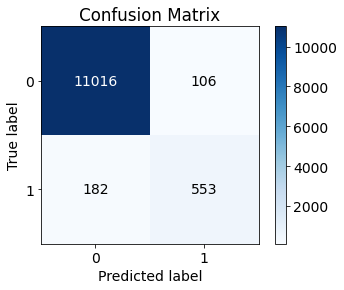

In [650]:
#gráficamos la matriz de confusión de los resultados
skplt.metrics.plot_confusion_matrix(y_test, y_predicted, labels=[0,1])

**Regresión logistica con hiperparámetros optimizados**

In [651]:
#Modelo con hiperparametros optimizados
model_hiper_log= LogisticRegression(C=3, class_weight={0:0.3,1:0.7},
                              n_jobs=-1, random_state=42)

In [652]:
#Entrenamiento del modelo
model_hiper_log.fit(X_train, y_train)

LogisticRegression(C=3, class_weight={0: 0.3, 1: 0.7}, n_jobs=-1,
                   random_state=42)

In [653]:
#Predicción
y_predicted = model_hiper_log.predict(X_test) 

<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

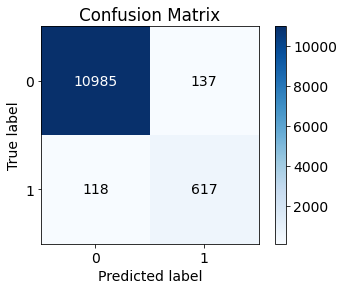

In [654]:
#Gráficamos la matriz de confusión con hiperparametros optimizados
skplt.metrics.plot_confusion_matrix(y_test, y_predicted, labels=[0,1])

In [655]:
#evaluamos con F1 score
f1_score(y_test, y_predicted)

0.8287441235728678

In [656]:
#evaluamos el recall score
recall_score(y_test, y_predicted)

0.8394557823129252

In [657]:
#scoring por cliente optimizado
df_prob_log = pd.DataFrame(model_hiper_log.predict_proba(X_test))
df_prob_log.sample(30)

,0,1
6754,0.998852,0.001148
10855,0.966779,0.033221
7220,0.970068,0.029932
605,0.999337,0.000663
10734,0.970040,0.029960
10710,0.344436,0.655564
10214,0.999526,0.000474
8134,0.943864,0.056136
3256,0.971373,0.028627
4414,0.991788,0.008212


### **Random Forest**:

In [658]:
#creamos una variable para el RandomForest
random_forest = RandomForestClassifier(n_estimators=200,random_state=42)

In [659]:
#entrenamos el algoritmo
random_forest.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [660]:
#visualizamos los parámetros
random_forest.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'n_estimators': 200,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [661]:
#predicción
y_predicted = random_forest.predict(X_test)

In [662]:
#evaluamos el algoritmo
random_forest.score(X_test, y_test)

0.9744454752466897

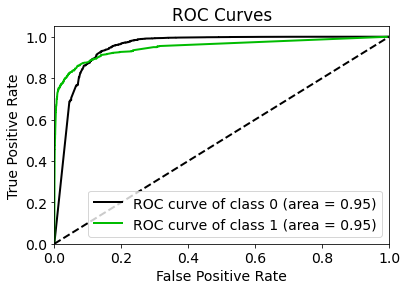

In [663]:
#analizamos métricas con el roc_auc(área bajo la curva)
skplt.metrics.plot_roc(y_test, random_forest.predict_proba(X_test), plot_micro=False, plot_macro=False)
plt.show()

In [664]:
#resultados scoring área bajo la curva
print(roc_auc_score(y_test, y_predicted))

0.8459734766051719


In [665]:
#evaluamos con F1 score
f1_score(y_test, y_predicted)

0.772351615326822

In [666]:
#evaluamos el recall score
recall_score(y_test, y_predicted)

0.6993197278911565

<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

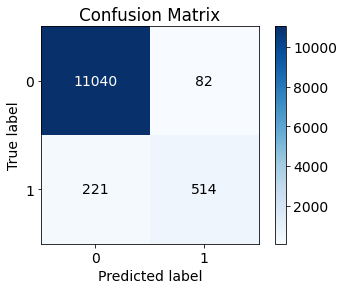

In [667]:
#gráficamos la matriz de confusión
skplt.metrics.plot_confusion_matrix(y_test, y_predicted)

In [668]:
#scoring por cliente
df_prob_rf = pd.DataFrame(random_forest.predict_proba(X_test))
df_prob_rf

,0,1
0,1.000000,0.000000
1,1.000000,0.000000
2,0.884761,0.115239
3,1.000000,0.000000
4,0.941006,0.058994
...,...,...
11852,1.000000,0.000000
11853,1.000000,0.000000
11854,0.995000,0.005000
11855,1.000000,0.000000


In [669]:
random_forest.predict_proba(X_test)

array([[1.        , 0.        ],
       [1.        , 0.        ],
       [0.88476114, 0.11523886],
       ...,
       [0.995     , 0.005     ],
       [1.        , 0.        ],
       [1.        , 0.        ]])

In [670]:
#analizamos el peso de cada variable en el modelo
random_forest.feature_importances_

array([0.02020118, 0.06582874, 0.02599025, 0.02151886, 0.02309   ,
       0.153946  , 0.02483504, 0.06776466, 0.2123745 , 0.06023696,
       0.08412769, 0.03858582, 0.09158428, 0.02702357, 0.04918377,
       0.03370867])

In [671]:
#columnas de df_model, verificamos peso de las variables
df_X.columns

Index(['sexo', 'contactos_realizados', 'importe_ultimo_cmax', 'limite_max',
       'limite_tarjeta', 'duracion_llamadas', 'llamada_entrante',
       'llamada_saliente', 'Final_NEGATIVO', 'Final_NULOS',
       'Final_REPROGRAMADO', 'Final_REPRO_ARGUMENTADO', 'Final_SISTEMA',
       'FIJO', 'MOVIL', 'edad'],
      dtype='object')

**RandomForest con hiperparámetros optimizados**

In [672]:
#algoritmo con hiperparámetros optimizados
model_hiper_rf = RandomForestClassifier(n_estimators=2,
                                     max_depth=8,
                                     criterion='entropy',
                                     class_weight={0:0.1,1:0.9},
                                     n_jobs=-1,
                                     random_state=42)

In [673]:
#entrenamos el algoritmo
model_hiper_rf.fit(X_train, y_train)

RandomForestClassifier(class_weight={0: 0.1, 1: 0.9}, criterion='entropy',
                       max_depth=8, n_estimators=2, n_jobs=-1, random_state=42)

In [674]:
#variable para predicción
y_predicted = model_hiper_rf.predict(X_test)

In [675]:
#métrica f1 score
f1_score(y_test, y_predicted)

0.5836693548387096

In [676]:
#métrica recall score
recall_score(y_test, y_predicted)

0.7877551020408163

<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

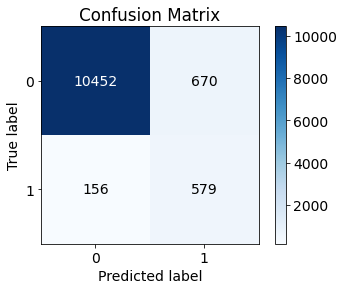

In [677]:
#matriz de confusión RandomForest
skplt.metrics.plot_confusion_matrix(y_test, y_predicted)

In [678]:
#scoring por cliente optimizado RandomForest
df_prob_rf = pd.DataFrame(model_hiper_rf.predict_proba(X_test))
df_prob_rf

,0,1
0,0.943890,0.056110
1,0.994678,0.005322
2,0.586830,0.413170
3,0.895204,0.104796
4,0.624071,0.375929
...,...,...
11852,0.986449,0.013551
11853,0.988857,0.011143
11854,0.759240,0.240760
11855,0.590781,0.409219


### **XGBoost**:

In [679]:
##creamos una variable para la el Gradient Boosting
model_xgb = XGBClassifier(random_state=42)

In [680]:
#entrenamos el modelo
model_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=42, ...)

In [681]:
#predicción
model_xgb.predict(X_test)  

array([0, 0, 0, ..., 0, 0, 0])

In [682]:
#scoring conjunto de entrenamiento
model_xgb.score(X_train, y_train)

0.9883964719491035

In [683]:
#scoring conjunto de test
model_xgb.score(X_test, y_test)

0.9796744539090833

In [684]:
#evaluamos el recall score
recall_score(y_test, y_predicted)

0.7877551020408163

In [685]:
#métrica f1 score
f1_score(y_test, y_predicted)

0.5836693548387096

<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

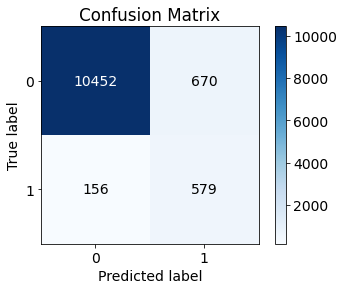

In [686]:
#Matriz de confusión inicial
skplt.metrics.plot_confusion_matrix(y_test, y_predicted)

**Gradient Boosting con hiperparametros optimizados**

In [687]:
#hiperparámetros del algoritmo
XGBClassifier().get_params()

{'objective': 'binary:logistic',
 'use_label_encoder': None,
 'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': None,
 'early_stopping_rounds': None,
 'enable_categorical': False,
 'eval_metric': None,
 'feature_types': None,
 'gamma': None,
 'gpu_id': None,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': None,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': None,
 'max_leaves': None,
 'min_child_weight': None,
 'missing': nan,
 'monotone_constraints': None,
 'n_estimators': 100,
 'n_jobs': None,
 'num_parallel_tree': None,
 'predictor': None,
 'random_state': None,
 'reg_alpha': None,
 'reg_lambda': None,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': None,
 'tree_method': None,
 'validate_parameters': None,
 'verbosity': None}

In [688]:
#optimización de hiperametros con MLFLOW
model_hiper_xgb = XGBClassifier(colsample_bytree = 0.7,
                            learning_rate = 0.4,
                            max_depth = 3,
                            n_estimators = 200,
                            subsample = 0.5,
                            n_jobs = -1,
                            random_state=42)

In [689]:
#entrenamiento
model_hiper_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.4, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=200, n_jobs=-1, num_parallel_tree=None,
              predictor=None, random_state=42, ...)

In [690]:
#variable de predicción
y_predicted = model_hiper_xgb.predict(X_test) 

In [691]:
#métrica f1 score
f1_score(y_test, y_predicted)

0.8243045387994143

In [692]:
#evaluamos el recall score
recall_score(y_test, y_predicted)

0.7659863945578231

<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

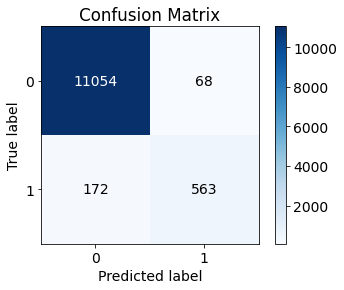

In [693]:
#Matriz de confusión con hiperparametros optimizados
skplt.metrics.plot_confusion_matrix(y_test, y_predicted)

In [694]:
##scoring por cliente optimizado XGBoosting
df_prob_xgb = pd.DataFrame(model_hiper_xgb.predict_proba(X_test))
df_prob_xgb

,0,1
0,0.993591,0.006409
1,0.997790,0.002210
2,0.977923,0.022077
3,0.992499,0.007501
4,0.936437,0.063563
...,...,...
11852,0.999576,0.000424
11853,0.999437,0.000563
11854,0.994499,0.005501
11855,0.996877,0.003123


## **Conclusiones:**

Con el objetivo de obtener el predict_proba (probabilidad de venta) entrenamos 3 algoritmos de clasificación para identificar cual se ajusta más a nuestros datos. Adicionalmente, efectuamos una búsqueda de hiperparámetros que nos pueda ayudar a mejorar las predicciones.

En conclusión el algoritmo que hasta el momento se ajusta más a nuestro propósito es la regresión logística, ya que en la matriz de confusión podemos visualizar un mayor acierto para los casos 1-1 el cúal es el objetivo del proyecto.